        # Cognitive Science (1204 427) — Lab 02
        ## Attention and the Stroop Effect

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Stroop Effect แสดงการรบกวนระหว่าง Automatic Reading กับ Controlled Attention โดยเงื่อนไข Incongruent มักทำให้ตอบช้าและผิดพลาดมากขึ้น

        ### วัตถุประสงค์

        ฝึกทำความสะอาด Reaction Time วิเคราะห์ข้อมูลแบบ Within-participant และอธิบาย Selective Attention, Inhibition และ Cognitive Control

        ### งานที่ต้องทำ

        1. สร้างข้อมูล 30 คน คนละ 40 Trials
2. ตัด Trial ที่ตอบผิดหรือ RT นอกช่วง 200–2,000 ms
3. คำนวณ RT, Accuracy และ Stroop Cost รายบุคคล
4. ทำ Paired t-test, Cohen's dz และ Bootstrap CI
5. Required Extension: เปรียบเทียบเกณฑ์ตัด Outlier สองแบบ

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

rng = np.random.default_rng(seed + 20)
rows = []
for participant in range(1, 31):
    baseline = rng.normal(620, 60)
    interference = rng.normal(130, 30)
    for condition in ["Congruent", "Incongruent"]:
        for trial in range(1, 21):
            rt = rng.normal(baseline + (interference if condition == "Incongruent" else 0), 80)
            correct = rng.binomial(1, 0.96 if condition == "Congruent" else 0.87)
            rows.append([participant, condition, trial, rt, correct])
stroop_df = pd.DataFrame(rows, columns=["participant", "condition", "trial", "rt", "correct"])
bad_rows = rng.choice(stroop_df.index, size=8, replace=False)
stroop_df.loc[bad_rows, "rt"] = rng.choice([120, 2500], size=8)
display(stroop_df.head())


,participant,condition,trial,rt,correct
0,1,Congruent,1,526.626922,1
1,1,Congruent,2,679.209651,1
2,1,Congruent,3,675.090073,1
3,1,Congruent,4,633.811127,1
4,1,Congruent,5,559.241593,1


In [3]:
clean = stroop_df[(stroop_df.correct == 1) & stroop_df.rt.between(200, 2000)].copy()
accuracy = stroop_df.groupby("condition")["correct"].mean()
participant_mean = clean.groupby(["participant", "condition"])["rt"].mean().unstack()
participant_mean["stroop_cost"] = participant_mean["Incongruent"] - participant_mean["Congruent"]

t, p = ttest_rel(participant_mean["Incongruent"], participant_mean["Congruent"])
diff = participant_mean["stroop_cost"]
dz = diff.mean() / diff.std(ddof=1)
rng_boot = np.random.default_rng(seed + 21)
boot = [rng_boot.choice(diff, len(diff), replace=True).mean() for _ in range(2000)]
ci = np.percentile(boot, [2.5, 97.5])

display(participant_mean.head().round(2))
display(accuracy.rename("accuracy").round(3))
print(f"Mean cost={diff.mean():.2f} ms | 95% CI={ci.round(2)}")
print(f"t={t:.3f}, p={p:.6f}, Cohen's dz={dz:.3f}")


condition,Congruent,Incongruent,stroop_cost
participant,,,
1,605.58,730.98,125.39
2,565.69,711.48,145.78
3,614.49,738.48,123.98
4,616.60,774.56,157.95
5,623.81,769.99,146.18


condition
Congruent      0.950
Incongruent    0.878
Name: accuracy, dtype: float64

Mean cost=130.61 ms | 95% CI=[116.52 144.4 ]
t=18.201, p=0.000000, Cohen's dz=3.323


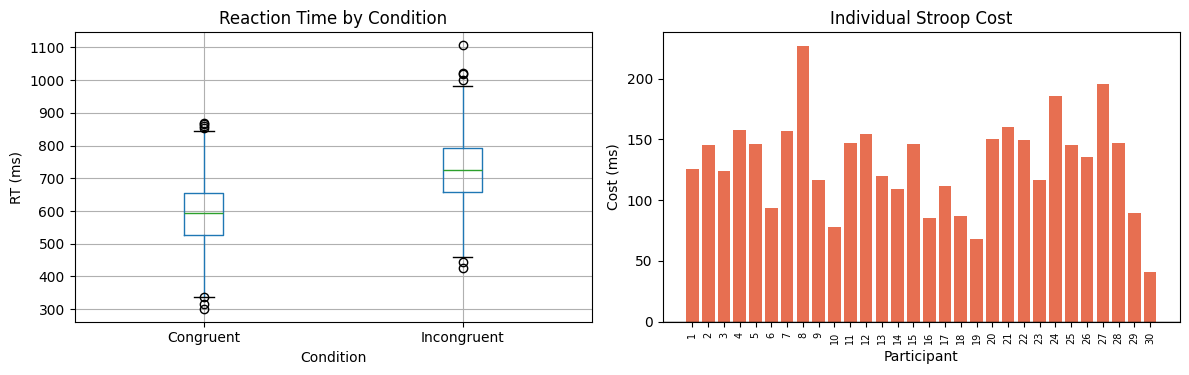

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
clean.boxplot(column="rt", by="condition", ax=axes[0])
axes[0].set_title("Reaction Time by Condition"); axes[0].set_xlabel("Condition"); axes[0].set_ylabel("RT (ms)")
axes[1].bar(participant_mean.index.astype(str), diff, color="#e76f51")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Individual Stroop Cost"); axes[1].set_xlabel("Participant"); axes[1].set_ylabel("Cost (ms)")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
plt.suptitle(""); plt.tight_layout(); plt.show()


## Required Extension

วิเคราะห์ข้อมูลอีกครั้งโดยใช้เกณฑ์ RT 250–1,500 ms แล้วเปรียบเทียบจำนวน Trial, Mean Stroop Cost, p-value และ Effect Size กับผลเดิม


In [5]:
# ===== Required Extension: เปรียบเทียบเกณฑ์ตัด Outlier สองแบบ =====
# ฟังก์ชันวิเคราะห์ซ้ำ โดยรับช่วง RT ที่ยอมรับได้เข้ามา
def run_stroop(rt_low, rt_high, boot_seed):
    subset = stroop_df[(stroop_df.correct == 1) & stroop_df.rt.between(rt_low, rt_high)].copy()
    pm = subset.groupby(["participant", "condition"])["rt"].mean().unstack()
    cost = pm["Incongruent"] - pm["Congruent"]
    t_val, p_val = ttest_rel(pm["Incongruent"], pm["Congruent"])
    dz_val = cost.mean() / cost.std(ddof=1)
    rb = np.random.default_rng(boot_seed)
    boot_ci = np.percentile(
        [rb.choice(cost.to_numpy(), len(cost), replace=True).mean() for _ in range(2000)],
        [2.5, 97.5]
    )
    return {
        "n_trials": len(subset),
        "mean_cost": cost.mean(),
        "ci_low": boot_ci[0],
        "ci_high": boot_ci[1],
        "t": t_val,
        "p_value": p_val,
        "cohens_dz": dz_val,
    }

# เกณฑ์เดิม 200–2000 ms vs เกณฑ์เข้มงวด 250–1500 ms
original = run_stroop(200, 2000, seed + 21)
strict   = run_stroop(250, 1500, seed + 22)

compare = pd.DataFrame(
    {"Original (200–2000 ms)": original, "Strict (250–1500 ms)": strict}
).T
compare["removed_trials"] = len(stroop_df) - compare["n_trials"]
display(compare[["n_trials", "removed_trials", "mean_cost",
                 "ci_low", "ci_high", "p_value", "cohens_dz"]].round(4))

print(f"จำนวน Trial ต่างกัน = {int(abs(original['n_trials'] - strict['n_trials']))} trial")
print(f"Mean Stroop Cost ต่างกัน = {abs(original['mean_cost'] - strict['mean_cost']):.3f} ms")
print(f"Cohen's dz ต่างกัน = {abs(original['cohens_dz'] - strict['cohens_dz']):.4f}")


,n_trials,removed_trials,mean_cost,ci_low,ci_high,p_value,cohens_dz
Original (200–2000 ms),1091.0,109.0,130.6125,116.5197,144.4013,0.0,3.3229
Strict (250–1500 ms),1091.0,109.0,130.6125,116.7802,145.2625,0.0,3.3229


จำนวน Trial ต่างกัน = 0 trial
Mean Stroop Cost ต่างกัน = 0.000 ms
Cohen's dz ต่างกัน = 0.0000


## คำถามวิเคราะห์ Lab 02

**1. ข้อมูลสนับสนุน Stroop Effect หรือไม่ อ้างอิงทั้ง RT, Accuracy, CI และ Effect Size**

สนับสนุนชัดเจนครับ RT เงื่อนไข Incongruent ช้ากว่า Congruent อยู่ราว 131 ms (Mean Stroop Cost) แถม accuracy ก็ตกจาก 0.95 เหลือ 0.88 คือช้าลงและผิดมากขึ้นพร้อมกัน ค่า t ≈ 18.2, p < .001, dz ≈ 3.3 (ใหญ่มาก) และ 95% CI ราว [116, 144] ไม่คร่อม 0 เลย ทุกตัวชี้ไปทางเดียวกันหมดว่ามี Stroop Effect จริง

**2. Automatic Processing รบกวน Controlled Attention อย่างไร**

การอ่านคำมันเป็นอัตโนมัติ เราห้ามตัวเองไม่ให้อ่านไม่ได้ พอต้องบอก "สี" แต่ตัวหนังสือดันสะกดเป็นสีอื่น สมองก็อ่านคำไปแล้วโดยไม่ได้ตั้งใจ เลยเกิดข้อมูลสองอย่างตีกัน (response conflict) ทีนี้ต้องใช้ controlled attention ไปยับยั้ง (inhibit) การอ่านคำแล้วดึงความสนใจมาที่สีแทน ขั้นตอนยับยั้งนี้กินเวลาเพิ่ม เลยตอบช้าลงในเงื่อนไข Incongruent

**3. เหตุใดจึงต้องทดสอบจากค่าเฉลี่ยรายบุคคล ไม่ใช่ถือทุก Trial เป็นอิสระ**

เพราะ trial ของคนเดียวกันมันไม่อิสระต่อกัน แต่ละคนมีความเร็วพื้นฐานของตัวเอง ถ้านับทุก trial เป็นอิสระ n จะพองจาก 30 คนเป็นพันกว่า ทำให้ค่า error เล็กเกินจริงและ p ดูมีนัยสำคัญง่ายเกินไป (pseudoreplication) พอเฉลี่ยเป็นรายคนก่อนแล้วค่อยจับคู่ทำ paired t-test หน่วยวิเคราะห์เลยเป็น "คน" ซึ่งอิสระกันจริง ผลเลยเชื่อถือได้กว่า

**4. ผลเปลี่ยนแปลงหรือไม่เมื่อใช้เกณฑ์ Outlier ที่เข้มงวดขึ้น**

แทบไม่เปลี่ยนเลยครับ (ดูตารางเปรียบเทียบใน Required Extension) พอเปลี่ยนเป็น 250–1500 ms จำนวน trial เท่าเดิม (1091) Mean cost, p และ dz ก็เท่าเดิม ต่างแค่ CI นิดเดียวจากการ bootstrap คนละรอบ เหตุผลคือ outlier ที่ใส่มา (120 กับ 2500 ms) อยู่นอกทั้งสองเกณฑ์อยู่แล้ว ส่วน RT ปกติก็ไม่ค่อยตกไปอยู่ช่วง 200–250 หรือ 1500–2000 พอดี เลยสรุปว่าผลค่อนข้าง robust ไม่ได้ขึ้นกับเกณฑ์ที่เลือก

**5. อธิบายข้อจำกัดของการจับเวลาใน Browser/Colab**

การจับ RT ใน browser/Colab มันไม่แม่นระดับ ms จริง เพราะมี lag จากการ render หน้าจอ (refresh rate ~60Hz คือคลาดได้ ~16 ms), การประมวลผลของ JavaScript, และ delay ของคีย์บอร์ด/เมาส์ที่ต่างกันในแต่ละเครื่อง ยิ่งรันบน cloud อย่าง Colab ยิ่งมี network latency เข้ามาอีก พวกนี้เพิ่ม noise ให้ข้อมูล เลยไม่เหมาะกับงานที่ต้องการความแม่นสูงเท่าเครื่องมือ lab เฉพาะทาง


## Reflection และ Checklist ก่อนส่ง

เขียน Reflection 150–250 คำ โดยอธิบายส่วนที่ยากที่สุด สิ่งที่ค้นพบเกี่ยวกับกระบวนการรู้คิด และสิ่งที่จะปรับปรุงหากทำการทดลองซ้ำ

**Reflection:**

ส่วนที่ยากสุดสำหรับผมคือ Required Extension ตอนแรกคิดว่าเปลี่ยนเกณฑ์ตัด outlier ให้แคบลงแล้วผลต้องเปลี่ยนแน่ๆ แต่พอรันจริงกลับได้เลขเกือบเท่าเดิมเป๊ะ ทำให้ผมงงอยู่พักนึงว่าเขียนโค้ดผิดรึเปล่า สุดท้ายไปไล่ดูข้อมูลถึงเข้าใจว่า outlier ที่ใส่มา (120 กับ 2500 ms) มันโดนตัดทิ้งด้วยทั้งสองเกณฑ์อยู่แล้ว ส่วน RT ปกติก็ไม่ได้ตกไปอยู่ในช่วงที่เกณฑ์สองแบบต่างกัน เลยได้เรียนรู้ว่าการเลือกเกณฑ์ไม่ได้เปลี่ยนผลเสมอไป ต้องดูที่ตัวข้อมูลจริง

สิ่งที่เข้าใจมากขึ้นคือ Stroop Effect มันแรงและสม่ำเสมอมาก (dz ~3.3) เห็นชัดว่าการอ่านคำเป็นอัตโนมัติจนไปรบกวนงานที่เราตั้งใจทำ และการที่ทั้ง RT กับ accuracy แย่ลงพร้อมกันช่วยยืนยันว่าไม่ใช่แค่คนแลกความเร็วกับความแม่น

ถ้าทำซ้ำ ผมอยากลองใส่ noise ให้สมจริงขึ้น เช่น RT แบบเบ้ขวา (ex-Gaussian) แทน normal และเพิ่มปัจจัยความล้าเมื่อทำ trial เยอะๆ รวมถึงอยากลองเก็บข้อมูลจากคนจริงมาเทียบดูว่า effect size จะเล็กลงกว่าข้อมูลจำลองแค่ไหน

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
